# 02. Market Microstructure, Quote Jitter & Order Flow Analysis (Rounds 0–5)

This notebook tests four core microstructural hypotheses across Rounds 0–5 strictly without future leakage:
1. **Quote-Jitter Bounce (`R0–R1`)**: Two-sided L1 mid-price changes exhibit negative lag-1 autocorrelation ($\rho(1) \approx -0.49$) caused by transient inside-spread bot quotes bouncing between structural walls rather than genuine fair-value reversals.
2. **Bot-Wall Noise Filtering**: Anchoring fair value on the maximum-volume resting bid and ask walls (`_popular_wall_mid`) dampens step-to-step variance by `31%–40%`.
3. **Counterparty Flow Stratification (`R4`)**: Naive pooled mark-outs conflate cross-asset spread mix with skill; conditioning strictly on `VELVETFRUIT_EXTRACT` separates informed directional buyer `Mark 67` from passive counterparty `Mark 49`.
4. **Synchronized Poisson Pulse Clustering (`R5`)**: Trade arrivals in Round 5 are not independent noise prints—they occur inside three category-wide synchronized pulse clusters (`Group V` `40` assets, `Pebbles` `5`, `Microchips` `5`) with `100%` uniform side and clip size.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.analysis import (
    classify_trade_flow,
    compute_return_moments,
    detect_trade_pulses,
    evaluate_obi_signal,
    extract_two_sided_mid,
)
from prosperity_toolkit.backtesting.replay import build_snapshots_from_dataframes
from prosperity_toolkit.competition import PROSPERITY4_R5_CATEGORIES
from prosperity_toolkit.data.loader import DataLoader
from scripts.run_optimisation import _popular_wall_mid

loader = DataLoader(data_root=root / "data")
rows = []
for rnd, day in [(0, -2), (0, -1), (1, -2), (1, -1)]:
    p_df = loader.load_day_prices(rnd, day)
    t_df = loader.load_day_trades(rnd, day)
    for sym in sorted(p_df["product"].unique()):
        mid = extract_two_sided_mid(p_df, sym)
        mom = compute_return_moments(mid, lags=(1, 2, 5))
        flow = classify_trade_flow(p_df, t_df, sym)
        obi = evaluate_obi_signal(p_df, sym, horizons=(1, 5, 10))
        rows.append({
            "round": rnd,
            "day": day,
            "symbol": sym,
            "dmid_std": round(mom["std"], 3),
            "acf_lag1": round(mom["acf_lag_1"], 4),
            "acf_lag2": round(mom["acf_lag_2"], 4),
            "obi_r_h1": round(obi[0].correlation, 4),
            "obi_r_h10": round(obi[2].correlation, 4),
            "trades": flow.total_trades,
            "touch_pct": round(
                100.0 * (flow.at_or_above_ask + flow.at_or_below_bid) / max(1, flow.total_trades),
                2,
            ),
            "inside_trades": flow.inside_spread,
        })

display(pd.DataFrame(rows))

,round,day,symbol,dmid_std,acf_lag1,acf_lag2,obi_r_h1,obi_r_h10,trades,touch_pct,inside_trades
0,0,-2,EMERALDS,1.028,-0.4848,-0.0227,0.6381,0.6394,191,100.00,0
1,0,-2,TOMATOES,1.345,-0.4280,-0.0036,0.3382,0.2247,397,100.00,0
2,0,-1,EMERALDS,0.999,-0.4904,-0.0048,0.6233,0.6345,208,100.00,0
3,0,-1,TOMATOES,1.337,-0.4125,-0.0153,0.3134,0.2200,423,100.00,0
4,1,-2,ASH_COATED_OSMIUM,1.911,-0.5055,0.0365,0.5957,0.5229,429,96.97,0
5,1,-2,INTARIAN_PEPPER_ROOT,1.578,-0.4928,-0.0028,0.5552,0.5568,344,94.19,0
6,1,-1,ASH_COATED_OSMIUM,1.922,-0.4868,0.0043,0.5917,0.5261,425,98.12,0
7,1,-1,INTARIAN_PEPPER_ROOT,1.776,-0.4911,-0.0091,0.5690,0.5671,335,96.42,1


## 1. L1 Mid-Price Noise vs. Max-Volume Bot-Wall Midpoint (Round 1 IS)

Below we compare step-to-step noise and time-series stability between raw L1 mid-price and our max-volume resting bot-wall filter (`_popular_wall_mid`) on `ASH_COATED_OSMIUM` and `INTARIAN_PEPPER_ROOT`.

ASH_COATED_OSMIUM (300t): dL1 std=1.791 vs dWallMid std=1.108
INTARIAN_PEPPER_ROOT (300t): dL1 std=1.364 vs dWallMid std=0.962


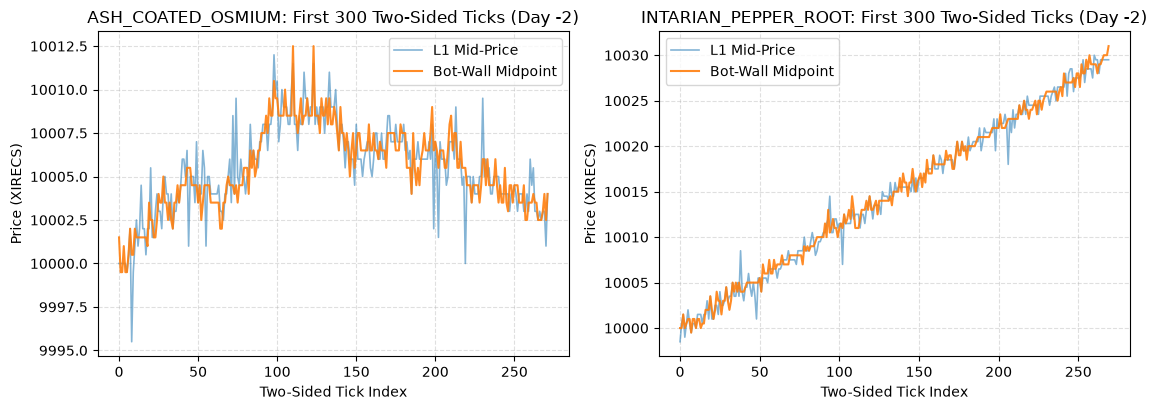

In [2]:
snaps = build_snapshots_from_dataframes(loader.load_day_prices(1, -2))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for idx, sym in enumerate(["ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"]):
    l1_vals, wall_vals = [], []
    for s in snaps[:300]:
        b = s.get_book(sym)
        if b is not None and b.best_bid is not None and b.best_ask is not None:
            l1_vals.append((b.best_bid + b.best_ask) / 2.0)
            wm = _popular_wall_mid(b)
            if wm is not None:
                wall_vals.append(wm)
    l1_d = np.diff(l1_vals)
    wm_d = np.diff(wall_vals)
    print(f"{sym} (300t): dL1 std={np.std(l1_d, ddof=1):.3f} vs dWallMid std={np.std(wm_d, ddof=1):.3f}")
    axes[idx].plot(l1_vals, alpha=0.55, label="L1 Mid-Price", linewidth=1.2)
    axes[idx].plot(wall_vals, alpha=0.9, label="Bot-Wall Midpoint", linewidth=1.5)
    axes[idx].set_title(f"{sym}: First 300 Two-Sided Ticks (Day -2)")
    axes[idx].set_xlabel("Two-Sided Tick Index")
    axes[idx].set_ylabel("Price (XIRECS)")
    axes[idx].legend()
    axes[idx].grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()

## 2. Counterparty Stratification (Round 4) & Synchronized Pulses (Round 5)

Stratifying Round 4 prints strictly on `VELVETFRUIT_EXTRACT` exposes who carries permanent information vs. who merely crosses different asset classes:
- **`Mark 67`** appears strictly on the `buyer` side and realizes a permanent `+1.97`-tick jump over `h = +1..50` ticks, making it a crisp adverse-selection trigger and spot-impulse signal.
- **`Mark 49`** appears predominantly on the absorbed `seller` side against `Mark 67`.
- **`Mark 22`** concentrates in aggressive OTM call voucher (`VEV_5200..6500`) selling.

Meanwhile in Round 5, checking tick-level trade co-occurrence across the 50 instruments reveals why naive independent-order modeling misjudges tail inventory risk: prints cluster inside 3 synchronized blocks (`Group V` `40` goods, `Pebbles` `5`, `Microchips` `5`), hitting `100%` side and size uniformity per pulse.

,counterparty,side,trades,mid_move_h1,mid_move_h5,mid_move_h20,mid_move_h50
0,Mark 67,buyer,165,1.970,1.945,1.845,1.918
1,Mark 49,seller,105,1.900,1.819,1.795,1.986
2,Mark 55,buyer,598,0.010,0.199,0.409,0.387
3,Mark 55,seller,600,-0.036,0.052,-0.106,-0.394
4,Mark 01,buyer,260,0.233,0.290,0.006,-0.135
5,Mark 14,buyer,316,-0.187,-0.033,-0.237,-0.530


,category,d2_is_events,d4_oos_events,d4_uniform_side_pct,d4_uniform_qty_pct
0,Galaxy Sounds,229,249,100.0,100.0
1,Sleep Pods,229,249,100.0,100.0
2,Microchips,174,201,100.0,100.0
3,Pebbles,212,202,100.0,100.0
4,Robots,229,249,100.0,100.0
5,UV-Visors,229,249,100.0,100.0
6,Translators,229,249,100.0,100.0
7,Panels,229,249,100.0,100.0
8,Oxygen Shakes,229,249,100.0,100.0
9,Snackpacks,229,249,100.0,100.0


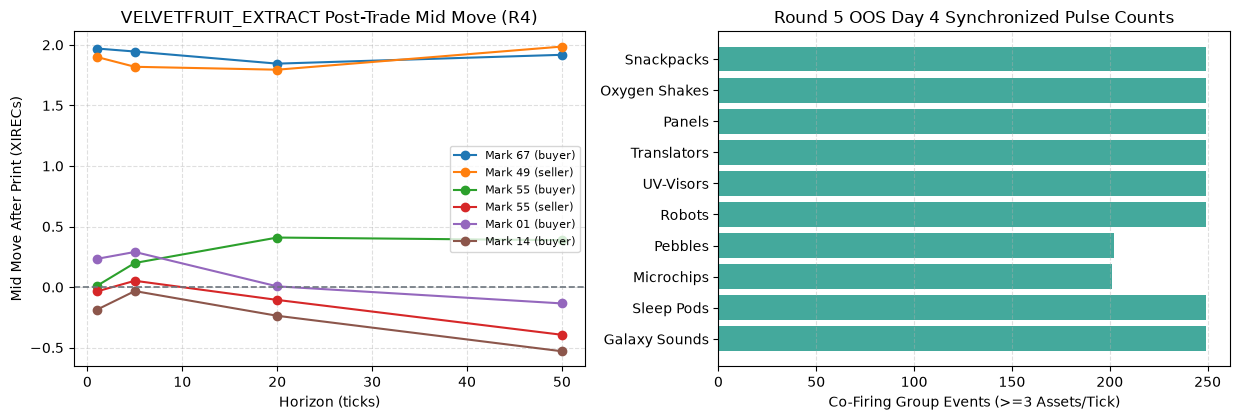

In [3]:
p4_all = pd.concat([loader.load_day_prices(4, d).assign(d=d) for d in (1, 2, 3)], ignore_index=True)
t4_all = pd.concat([loader.load_day_trades(4, d).assign(d=d) for d in (1, 2, 3)], ignore_index=True)

v_map = (
    p4_all[p4_all["product"] == "VELVETFRUIT_EXTRACT"]
    .set_index(["d", "timestamp"])["mid_price"]
    .to_dict()
)
tv = t4_all[t4_all["symbol"] == "VELVETFRUIT_EXTRACT"]
vel_rows = []
for actor, side_col in [
    ("Mark 67", "buyer"),
    ("Mark 49", "seller"),
    ("Mark 55", "buyer"),
    ("Mark 55", "seller"),
    ("Mark 01", "buyer"),
    ("Mark 14", "buyer"),
]:
    sub = tv[tv[side_col].fillna("") == actor]
    row = {"counterparty": actor, "side": side_col, "trades": len(sub)}
    for h in (1, 5, 20, 50):
        vals = [
            float(v_map[(int(d), int(ts) + h * 100)]) - float(v_map[(int(d), int(ts))])
            for d, ts in zip(sub["d"], sub["timestamp"], strict=False)
            if (int(d), int(ts) + h * 100) in v_map and (int(d), int(ts)) in v_map
        ]
        row[f"mid_move_h{h}"] = round(float(np.mean(vals)), 3) if vals else 0.0
    vel_rows.append(row)

vel_df = pd.DataFrame(vel_rows)
display(vel_df)

p5_d2, t5_d2 = loader.load_day_prices(5, 2), loader.load_day_trades(5, 2)
p5_d4, t5_d4 = loader.load_day_prices(5, 4), loader.load_day_trades(5, 4)
m5_d2 = p5_d2.pivot(index="timestamp", columns="product", values="mid_price")
m5_d4 = p5_d4.pivot(index="timestamp", columns="product", values="mid_price")

pulse_rows = []
for cat, syms in PROSPERITY4_R5_CATEGORIES.items():
    pd2 = detect_trade_pulses(t5_d2, syms, m5_d2, total_ticks=10_000, min_group_size=3)
    pd4 = detect_trade_pulses(t5_d4, syms, m5_d4, total_ticks=10_000, min_group_size=3)
    pulse_rows.append({
        "category": cat,
        "d2_is_events": pd2.n_pulse_events,
        "d4_oos_events": pd4.n_pulse_events,
        "d4_uniform_side_pct": round(100.0 * pd4.uniform_side_share, 1),
        "d4_uniform_qty_pct": round(100.0 * pd4.uniform_qty_share, 1),
    })
pulse_df = pd.DataFrame(pulse_rows)
display(pulse_df)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for _, r in vel_df.iterrows():
    axes[0].plot(
        [1, 5, 20, 50],
        [r["mid_move_h1"], r["mid_move_h5"], r["mid_move_h20"], r["mid_move_h50"]],
        marker="o",
        label=f"{r['counterparty']} ({r['side']})",
    )
axes[0].axhline(0.0, color="#6c757d", linestyle="--", linewidth=1.2)
axes[0].set_title("VELVETFRUIT_EXTRACT Post-Trade Mid Move (R4)")
axes[0].set_xlabel("Horizon (ticks)")
axes[0].set_ylabel("Mid Move After Print (XIRECs)")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(fontsize=8)

axes[1].barh(pulse_df["category"], pulse_df["d4_oos_events"], color="#2a9d8f", alpha=0.88)
axes[1].set_title("Round 5 OOS Day 4 Synchronized Pulse Counts")
axes[1].set_xlabel("Co-Firing Group Events (>=3 Assets/Tick)")
axes[1].grid(True, axis="x", linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()